# 02 - Radioactive decay, half-life and decay chains

**MATH 331 - Differential Equations.** Syllabus units U2 (separable and linear first-order
equations, integrating factor) and U4 (growth and decay). Lecture plan: Sessions 4, 5 and 7.

**References**
* J. Lebl, *Notes on Diffy Qs* (`ode/FullText_Diff_Eq_For_Engineers.pdf`): Section 1.3
  (separable equations) and Section 1.4 (linear equations and the integrating factor).
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012), Sections
  1.1 and 1.3: the law of radioactive decay, half-life, radiocarbon dating (Example 8).

**What you will learn**
1. The decay law as an IVP, and its solution $N(t) = N_0 e^{-\lambda t}$.
2. Half-life and mean lifetime: what they mean and how they relate to $\lambda$.
3. Radiocarbon dating, with an honest look at its accuracy.
4. A **decay chain** (parent → daughter): a *linear, non-homogeneous* first-order equation
   solved with an integrating factor. It includes the special case where the textbook formula
   divides by zero.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (analytic solutions, Euler/Heun/RK4, slope fields, phase lines).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. The law of radioactive decay

The rate at which radioactive atoms disintegrate is proportional to the number of
radioactive atoms present (Adkins and Davidson, Section 1.1, Example 2). With $N(t)$ the number
of atoms (or the mass of the isotope) at time $t$:

$$
\boxed{\;\frac{dN}{dt} = -\lambda N, \qquad N(0) = N_0, \qquad \lambda > 0\;}
$$

* $\lambda$ is the **decay constant** (units $1/\text{time}$). The minus sign makes $N$ decrease.
  It is the equation of notebook 01 with $k = -\lambda < 0$.
* Each atom decays at random, independently of the others, with probability $\lambda\,dt$ in a
  short time $dt$. For a large number of atoms the expected number of decays is $\lambda N\,dt$,
  which gives the equation. The ODE describes the **expected** behaviour of a random process.

**Existence and uniqueness.** $f(t,N) = -\lambda N$ and $\partial f/\partial N = -\lambda$ are
continuous everywhere, so Picard's theorem (Lebl, Theorem 1.2.1) gives a unique solution
through every initial point.

**Solution** (separation of variables, exactly as in notebook 01, Lebl Section 1.3):

$$
N(t) = N_0\,e^{-\lambda t}.
$$

## 2. Half-life and mean lifetime

**Half-life** $\tau_{1/2}$: the time after which half of the atoms remain,
$N(\tau_{1/2}) = N_0/2$:

$$
N_0 e^{-\lambda \tau_{1/2}} = \tfrac12 N_0
\;\Longrightarrow\;
\boxed{\;\tau_{1/2} = \frac{\ln 2}{\lambda}\;}
$$

(Adkins and Davidson, eq. (12).) It **does not depend on $N_0$**. Going from 2 g to 1 g takes
as long as going from 1 g to 0.5 g. After $n$ half-lives a fraction $2^{-n}$ remains:
$N(t) = N_0\,2^{-t/\tau_{1/2}}$.

**Mean lifetime** $\bar\tau$. The probability that an atom survives up to time $t$ is
$N(t)/N_0 = e^{-\lambda t}$, so its lifetime has probability density $\lambda e^{-\lambda t}$, and

$$
\bar\tau = \int_0^\infty t\,\lambda e^{-\lambda t}\,dt = \frac{1}{\lambda}
\qquad\text{(integration by parts)},
\qquad \bar\tau = \frac{\tau_{1/2}}{\ln 2} \approx 1.443\,\tau_{1/2}.
$$

After one mean lifetime a fraction $1/e \approx 36.8\%$ remains.

**A log-linear plot reveals exponential decay.** $\ln N(t) = \ln N_0 - \lambda t$ is a straight line
with slope $-\lambda$. This is how $\lambda$ is measured in practice.

<IPython.core.display.Math object>

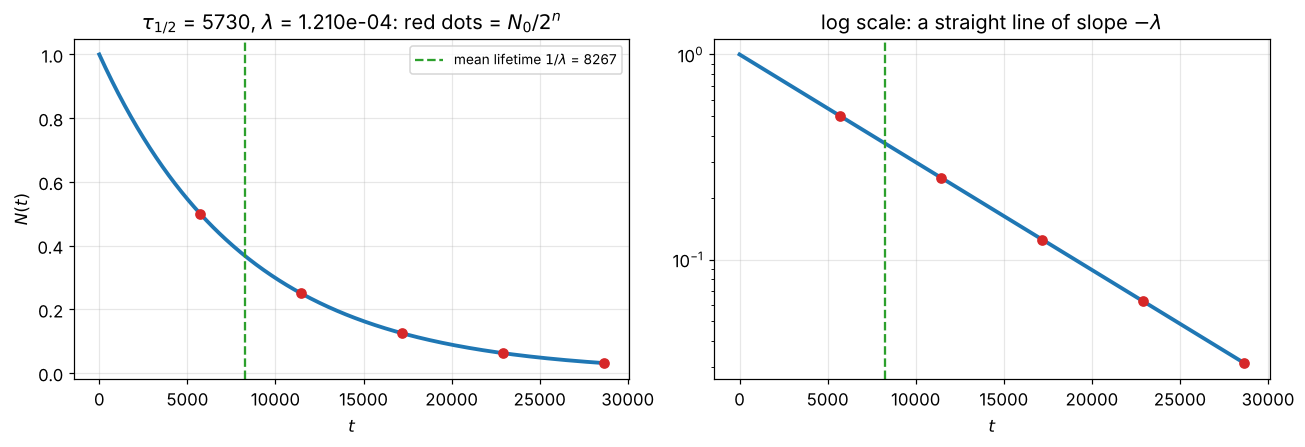

In [2]:
lam_sym, tt = sp.symbols("lambda t", positive=True)
mean_life = sp.integrate(tt * lam_sym * sp.exp(-lam_sym * tt), (tt, 0, sp.oo))
display(Math(r"\bar\tau = \int_0^\infty t\,\lambda e^{-\lambda t}\,dt = " + sp.latex(mean_life)))


def plot_decay(half_life=5730.0, N0=1.0, n_half_lives=5):
    """N(t) on linear and logarithmic axes, with half-lives and the mean lifetime marked."""
    lam = ol.decay_constant(half_life)
    t = np.linspace(0, n_half_lives * half_life, 400)
    N = ol.exponential_solution(t, N0, -lam)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax in (ax1, ax2):
        ax.plot(t, N, lw=2.5)
        for n in range(1, int(n_half_lives) + 1):
            ax.plot([n * half_life], [N0 * 2.0**-n], "o", color="C3")
        ax.axvline(1 / lam, color="C2", ls="--", label=rf"mean lifetime $1/\lambda$ = {1 / lam:.4g}")
        ax.set_xlabel("$t$")
    ax1.set_ylabel("$N(t)$")
    ax1.set_title(rf"$\tau_{{1/2}}$ = {half_life:.4g}, $\lambda$ = {lam:.3e}: red dots = $N_0/2^n$")
    ax2.set_yscale("log")
    ax2.set_title(r"log scale: a straight line of slope $-\lambda$")
    ax1.legend()
    plt.tight_layout()
    plt.show()


plot_decay()

**Explore** (running kernel): half-life, initial amount, length of the time window.

In [3]:
interact(plot_decay,
         half_life=FloatSlider(value=5730, min=1, max=10000, step=1, description="half-life",
                               continuous_update=False),
         N0=FloatSlider(value=1.0, min=0.1, max=10, step=0.1, description="N0", continuous_update=False),
         n_half_lives=IntSlider(value=5, min=1, max=10, description="window", continuous_update=False));

interactive(children=(FloatSlider(value=5730.0, continuous_update=False, description='half-life', max=10000.0,…

## 3. Radiocarbon dating (Adkins and Davidson, Example 8)

Carbon-14 decays into nitrogen-14 with a half-life of 5730 years. A living organism keeps the
same $^{14}$C/C ratio as the atmosphere; after death the $^{14}$C decays. If a fraction $f$ of the
original $^{14}$C remains, then $f = e^{-\lambda t}$, so

$$
t = -\frac{\ln f}{\lambda} = -\tau_{1/2}\,\frac{\ln f}{\ln 2}.
$$

> *A sample of wood contains 75 % of the $^{14}$C of a sample of wood found today. How old is it?*
> $\;t = -5730\,\ln 0.75/\ln 2 \approx 2378$ years.

**How accurate is the age?** Differentiating $t(f)$ gives $\dfrac{dt}{df} = -\dfrac{1}{\lambda f}$,
so a measurement error $\delta f$ produces an age error $|\delta t| \approx \dfrac{\delta f}{\lambda f}$.
It grows as $f$ gets small, so **old samples are harder to date**. Two more caveats:
* the atmospheric $^{14}$C ratio has not been constant, so laboratories correct ages with
  calibration curves (Adkins and Davidson, footnote 7);
* by convention, "radiocarbon ages" are computed with the older *Libby* half-life, 5568 years,
  and then calibrated. The physical half-life is about 5730 years.

age of the wood sample: 2378.2 years


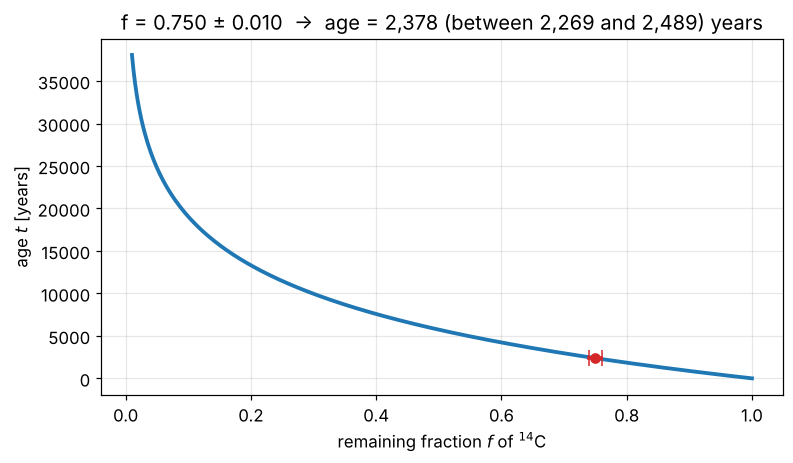

In [4]:
age = ol.age_from_fraction(0.75, 5730)
print(f"age of the wood sample: {age:.1f} years")
assert abs(age - 2378) < 0.5                     # Adkins and Davidson, Example 8


def plot_dating(fraction=0.75, delta_f=0.01):
    """Age as a function of the remaining fraction, with the effect of a measurement error."""
    half = 5730.0
    lam = ol.decay_constant(half)
    f = np.linspace(0.01, 1.0, 400)
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(f, -np.log(f) / lam, lw=2.5)
    t0 = ol.age_from_fraction(fraction, half)
    lo = ol.age_from_fraction(min(fraction + delta_f, 1.0), half)
    hi = ol.age_from_fraction(max(fraction - delta_f, 1e-6), half)
    ax.errorbar([fraction], [t0], xerr=[[delta_f], [delta_f]], yerr=[[t0 - lo], [hi - t0]],
                fmt="o", color="C3", capsize=5)
    ax.set_xlabel("remaining fraction $f$ of $^{14}$C")
    ax.set_ylabel("age $t$ [years]")
    ax.set_title(f"f = {fraction:.3f} ± {delta_f:.3f}  →  age = {t0:,.0f} "
                 f"(between {lo:,.0f} and {hi:,.0f}) years")
    plt.show()


plot_dating()

**Explore** (running kernel): measured fraction and its uncertainty.

In [5]:
interact(plot_dating,
         fraction=FloatSlider(value=0.75, min=0.02, max=0.99, step=0.01, description="fraction",
                              continuous_update=False),
         delta_f=FloatSlider(value=0.01, min=0.001, max=0.05, step=0.001, readout_format=".3f",
                             description="δf", continuous_update=False));

interactive(children=(FloatSlider(value=0.75, continuous_update=False, description='fraction', max=0.99, min=0…

## 4. A decay chain: parent → daughter → (stable)

Many isotopes decay into another radioactive isotope. With $N_P$ the parent and $N_D$ the
daughter atoms (decay constants $\lambda_P$, $\lambda_D$):

$$
\frac{dN_P}{dt} = -\lambda_P N_P, \qquad
\frac{dN_D}{dt} = \underbrace{\lambda_P N_P}_{\text{produced by the parent}}
                 - \underbrace{\lambda_D N_D}_{\text{own decay}},
\qquad N_P(0) = N_{P0},\; N_D(0) = N_{D0}.
$$

The first equation gives $N_P = N_{P0}e^{-\lambda_P t}$. Substituting it, the second becomes a
**linear first-order non-homogeneous** equation (Lebl, Section 1.4):

$$
N_D' + \lambda_D N_D = \lambda_P N_{P0}\,e^{-\lambda_P t}.
$$

**Integrating factor** $r(t) = e^{\int \lambda_D\,dt} = e^{\lambda_D t}$. Multiplying by $r$ turns
the left-hand side into an exact derivative:

$$
\frac{d}{dt}\left(e^{\lambda_D t} N_D\right) = \lambda_P N_{P0}\,e^{(\lambda_D - \lambda_P)t}.
$$

Integrating from $0$ to $t$:

* **if $\lambda_D \neq \lambda_P$** (the *Bateman* solution):
  $$N_D(t) = N_{D0}\,e^{-\lambda_D t} + \frac{\lambda_P N_{P0}}{\lambda_D - \lambda_P}
  \left(e^{-\lambda_P t} - e^{-\lambda_D t}\right);$$
* **if $\lambda_D = \lambda_P = \lambda$**: the right-hand side is the constant $\lambda N_{P0}$, so
  $$N_D(t) = \left(N_{D0} + \lambda N_{P0}\,t\right)e^{-\lambda t}.$$

The general formula divides by zero when $\lambda_D = \lambda_P$, but the special case is its
**limit** (l'Hôpital). Always check what happens at the edges of a formula's validity!

**Maximum of the daughter** (with $N_{D0} = 0$): setting $N_D' = 0$ gives
$t_{max} = \dfrac{\ln(\lambda_D/\lambda_P)}{\lambda_D - \lambda_P}$ ($= 1/\lambda$ in the equal case).

*Application.* Molybdenum-99 ($\tau_{1/2}\approx 66$ h) decays into technetium-99m
($\tau_{1/2}\approx 6$ h), the most widely used isotope in medical imaging. Hospitals receive Mo-99
"generators" and extract the Tc-99m that accumulates (in reality only about 88 % of the Mo-99
decays go to Tc-99m: multiply the source term by this branching ratio).

In [6]:
t = sp.symbols("t", nonnegative=True)
lP, lD, NP0, ND0 = sp.symbols("lambda_P lambda_D N_P0 N_D0", positive=True)
ND = sp.Function("N_D")
chain = sp.Eq(ND(t).diff(t), lP * NP0 * sp.exp(-lP * t) - lD * ND(t))
bateman = sp.dsolve(chain, ND(t), ics={ND(0): ND0}).rhs        # SymPy's own (messier) form

# The formula derived above with the integrating factor; check that it is the same function:
by_hand = ND0 * sp.exp(-lD * t) + lP * NP0 / (lD - lP) * (sp.exp(-lP * t) - sp.exp(-lD * t))
assert sp.simplify(bateman - by_hand) == 0
display(Math(r"N_D(t) = " + sp.latex(by_hand) + r"\quad\text{(equal to SymPy's dsolve result)}"))

# The equal-rates case as a limit of the general formula (l'Hopital):
lam = sp.symbols("lambda", positive=True)
equal_case = sp.limit(bateman.subs(lP, lam), lD, lam)
display(Math(r"\lim_{\lambda_D\to\lambda_P=\lambda} N_D(t) = " + sp.latex(sp.factor(equal_case))))
assert sp.simplify(equal_case - (ND0 + lam * NP0 * t) * sp.exp(-lam * t)) == 0

<IPython.core.display.Math object>

<IPython.core.display.Math object>

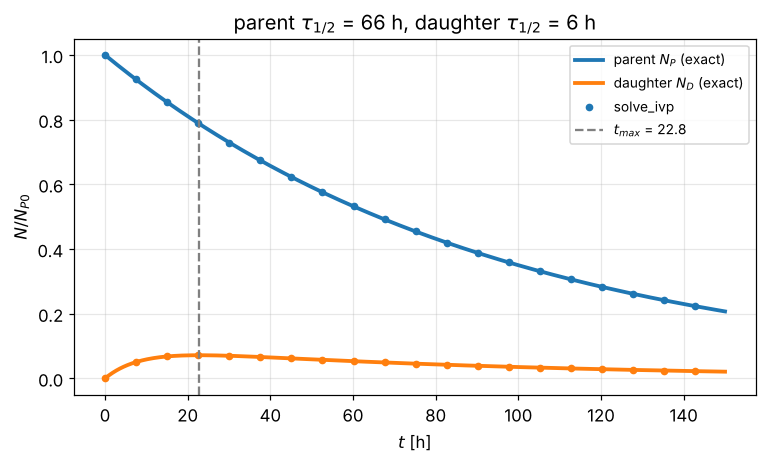

max |numerical - exact| for the daughter: 1.79e-12


In [7]:
def daughter(t, NP0, ND0, lam_P, lam_D):
    """Bateman solution for the daughter, including the equal-rates case."""
    if np.isclose(lam_P, lam_D, rtol=1e-12):
        return (ND0 + lam_P * NP0 * t) * np.exp(-lam_P * t)
    return (ND0 * np.exp(-lam_D * t)
            + lam_P * NP0 / (lam_D - lam_P) * (np.exp(-lam_P * t) - np.exp(-lam_D * t)))


def plot_chain(half_parent=66.0, half_daughter=6.0, t_end=150.0):
    """Parent and daughter populations: analytical (lines) vs numerical (dots)."""
    lam_P, lam_D = ol.decay_constant(half_parent), ol.decay_constant(half_daughter)
    t = np.linspace(0, t_end, 500)
    rhs = lambda tt, y: [-lam_P * y[0], lam_P * y[0] - lam_D * y[1]]      # noqa: E731
    num = solve_ivp(rhs, (0, t_end), [1.0, 0.0], rtol=1e-10, atol=1e-12, t_eval=t[::25])
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(t, np.exp(-lam_P * t), lw=2.5, label="parent $N_P$ (exact)")
    ax.plot(t, daughter(t, 1.0, 0.0, lam_P, lam_D), lw=2.5, label="daughter $N_D$ (exact)")
    ax.plot(num.t, num.y[0], "o", color="C0", ms=4, label="solve_ivp")
    ax.plot(num.t, num.y[1], "o", color="C1", ms=4)
    if not np.isclose(lam_P, lam_D):
        t_max = np.log(lam_D / lam_P) / (lam_D - lam_P)
    else:
        t_max = 1 / lam_P
    ax.axvline(t_max, color="0.5", ls="--", label=rf"$t_{{max}}$ = {t_max:.3g}")
    ax.set_xlabel("$t$ [h]")
    ax.set_ylabel(r"$N / N_{P0}$")
    ax.set_title(rf"parent $\tau_{{1/2}}$ = {half_parent:g} h, daughter $\tau_{{1/2}}$ = {half_daughter:g} h")
    ax.legend()
    plt.show()
    error = np.max(np.abs(num.y[1] - daughter(num.t, 1.0, 0.0, lam_P, lam_D)))
    print(f"max |numerical - exact| for the daughter: {error:.2e}")


plot_chain()

**Explore** (running kernel). Try three regimes:
* daughter much shorter-lived than the parent (e.g. 66 h and 6 h): after a while
  $N_D/N_P \to \lambda_P/(\lambda_D-\lambda_P)$ (*transient equilibrium*);
* equal half-lives: the special case, with the maximum at $t = 1/\lambda$;
* daughter longer-lived than the parent: the daughter decays slowly, after the parent is gone.

In [8]:
interact(plot_chain,
         half_parent=FloatSlider(value=66, min=1, max=200, step=1, description="parent τ½",
                                 continuous_update=False),
         half_daughter=FloatSlider(value=6, min=1, max=200, step=1, description="daughter τ½",
                                   continuous_update=False),
         t_end=FloatSlider(value=150, min=10, max=600, step=10, description="t max",
                           continuous_update=False));

interactive(children=(FloatSlider(value=66.0, continuous_update=False, description='parent τ½', max=200.0, min…

## 5. Exercises

1. Show that $N(t) = N_0\,2^{-t/\tau_{1/2}}$ is the same function as $N_0 e^{-\lambda t}$.
2. *(Adkins and Davidson, Section 1.3)* Repeat the radiocarbon computation for a sample with
   10 % of the original $^{14}$C. Using the error formula of Section 3, estimate the age
   uncertainty for $\delta f = 0.005$. Compare with the case $f = 0.75$.
3. Derive the Bateman solution yourself with the integrating factor, then verify it by
   substitution. Compute $\lim_{t\to\infty} N_D(t)/N_P(t)$ when $\lambda_D > \lambda_P$.
4. Explain why a decay chain with $\lambda_D = \lambda_P$ is not a "dangerous" case for the
   *differential equation* (Picard applies), only for the *formula*.
5. A capacitor $C$ discharges through a resistor $R$: $V' = -V/(RC)$. What plays the role of the
   half-life? What is the mean lifetime called in circuit theory?